In [4]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

project_path = Path("..").resolve()
sys.path.append(str(project_path))

In [5]:
patch_dir = "../data/raw/patches_64/images/"
patch_files = sorted(Path(patch_dir).glob("*.npy"))

print(f"Total patches: {len(patch_files)}")
print(f"First 10 patches: {[f.name for f in patch_files[:10]]}")



Total patches: 2244
First 10 patches: ['patch_64_00000001.npy', 'patch_64_00000002.npy', 'patch_64_00000003.npy', 'patch_64_00000004.npy', 'patch_64_00000005.npy', 'patch_64_00000006.npy', 'patch_64_00000007.npy', 'patch_64_00000008.npy', 'patch_64_00000009.npy', 'patch_64_00000010.npy']


In [6]:
first_patch = np.load(patch_files[0])
print(f"Patch shape: {first_patch.shape}")
print(f"Patch min: {first_patch.min():.3f}, max: {first_patch.max():.3f}")



Patch shape: (64, 64, 64)
Patch min: 224.000, max: 706.000


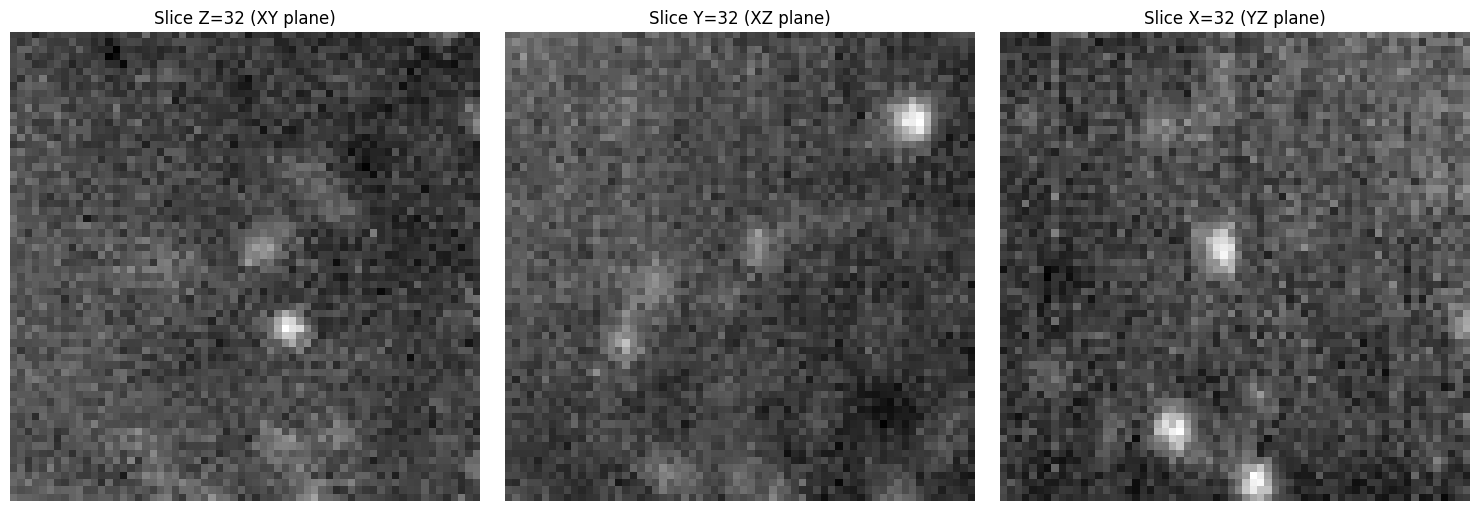

In [7]:
patch = first_patch
middle_z = patch.shape[0] // 2
middle_y = patch.shape[1] // 2
middle_x = patch.shape[2] // 2

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(patch[middle_z, :, :], cmap='gray')
axes[0].set_title(f'Slice Z={middle_z} (XY plane)')
axes[0].axis('off')

axes[1].imshow(patch[:, middle_y, :], cmap='gray')
axes[1].set_title(f'Slice Y={middle_y} (XZ plane)')
axes[1].axis('off')

axes[2].imshow(patch[:, :, middle_x], cmap='gray')
axes[2].set_title(f'Slice X={middle_x} (YZ plane)')
axes[2].axis('off')

plt.tight_layout()
plt.show()



In [8]:
mask_patch_dir = "../data/raw/patches_64/masks/"
mask_patch_files = sorted(Path(mask_patch_dir).glob("*.npy"))

first_mask = np.load(mask_patch_files[0])
print(f"Mask patch shape: {first_mask.shape}")
print(f"Mask unique values: {np.unique(first_mask)}")
print(f"Number of neurons in first patch: {first_mask.sum()}")



Mask patch shape: (64, 64, 64)
Mask unique values: [  0 255]
Number of neurons in first patch: 171615


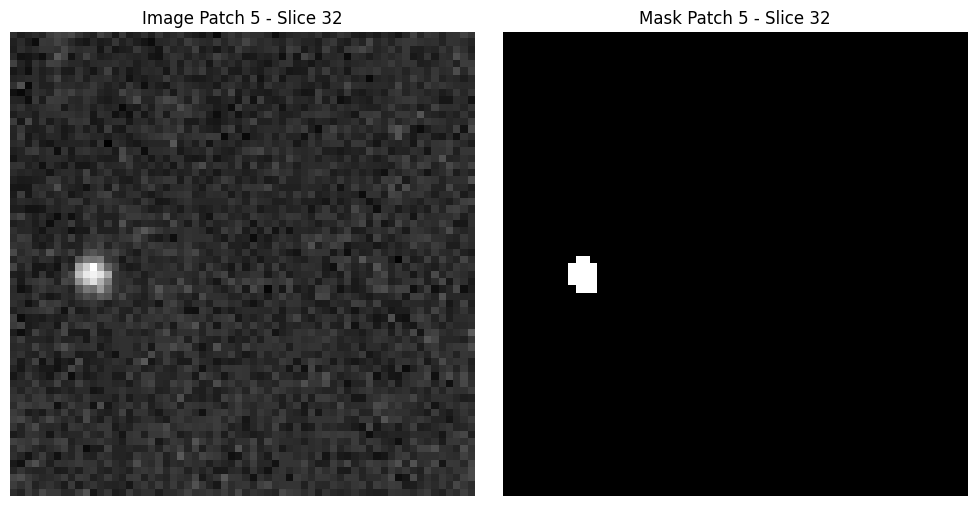

In [9]:
patch_idx = 5  
image_patch = np.load(patch_files[patch_idx])
mask_patch = np.load(mask_patch_files[patch_idx])

middle = image_patch.shape[0] // 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(image_patch[middle, :, :], cmap='gray')
ax1.set_title(f'Image Patch {patch_idx} - Slice {middle}')
ax1.axis('off')
ax2.imshow(mask_patch[middle, :, :], cmap='gray')
ax2.set_title(f'Mask Patch {patch_idx} - Slice {middle}')
ax2.axis('off')
plt.tight_layout()
plt.show()



In [10]:
neurons_per_patch = []
for mask_file in mask_patch_files[:100]:  
    mask = np.load(mask_file)
    neurons_per_patch.append(mask.sum())

print(f"Patches with neurons: {sum(1 for n in neurons_per_patch if n > 0)} / {len(neurons_per_patch)}")
print(f"Neurons per patch - min: {min(neurons_per_patch)}, max: {max(neurons_per_patch)}")
print(f"Neurons per patch - mean: {np.mean(neurons_per_patch):.2f}")



Patches with neurons: 96 / 100
Neurons per patch - min: 0, max: 644385
Neurons per patch - mean: 135277.50


In [ ]:
plt.figure(figsize=(10, 5))
plt.hist([n for n in neurons_per_patch if n > 0], bins=30)
plt.xlabel('Number of neurons per patch')
plt.ylabel('Number of patches')
plt.title('Distribution of neurons in patches')
plt.show()